In [14]:
import os
import numpy as np

import torch
import torch.nn as nn

import torchvision.datasets as dset
import torchvision.transforms as transforms

import pyro
import pyro.distributions as dist
import pyro.contrib.examples.util  # patches torchvision
from pyro.infer import SVI, Trace_ELBO
from pyro.optim import Adam

import matplotlib.pyplot as plt

In [35]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim1, hidden_dim2, n_markers):
        super().__init__()
        
        self.fc1 = nn.Linear(latent_dim, hidden_dim2)
        self.fc2 = nn.Linear(hidden_dim2, hidden_dim1)
        self.fc21 = nn.Linear(hidden_dim1, n_markers)
        
        #non-linearities
        self.softplus = nn.Softplus()
        self.sigmoid = nn.Sigmoid()
        self.relu = nn.ReLU()
    
    def forward(self, z):
        hidden1 = self.relu(self.fc1(z))
        hidden2 = self.relu(self.fc2(hidden1))
        loc_cell = self.sigmoid(self.fc21(hidden2))
        return loc_cell

In [36]:
class Encoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim1, hidden_dim2, n_markers):
        super().__init__()
        
        self.n_markers = n_markers
        self.fc1 = nn.Linear(n_markers, hidden_dim1)
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.fc21 = nn.Linear(hidden_dim2, latent_dim)
        self.fc22 = nn.Linear(hidden_dim2, latent_dim)
        
        #non-linearities
        self.softplus = nn.Softplus()
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = x.reshape(-1, self.n_markers)
        
        #compute hidden units
        hidden1 = self.relu(self.fc1(x))
        hidden2 = self.relu(self.fc2(hidden1))
        z_loc = self.fc21(hidden2)
        z_scale = torch.exp(self.fc22(hidden2))
        return z_loc, z_scale
    

In [37]:
class VAE(nn.Module):
    
    def __init__(self, latent_dim, hidden_dim1, hidden_dim2, n_markers, use_cuda=False ):
        super().__init__()
        self.encoder = Encoder(latent_dim, hidden_dim1, hidden_dim2, n_markers)
        self.decoder = Decoder(latent_dim, hidden_dim1, hidden_dim2, n_markers)
        
        self.use_cuda = use_cuda
        self.latent_dim = latent_dim
        
        self.n_markers = n_markers
    
    def model(self, x):
        pyro.module("decoder", self.decoder)
        with pyro.plate("data", x.shape[0]):
            
            #prior parameters
            
            z_loc = x.new_zeros(torch.Size((x.shape[0], self.latent_dim)))
            z_scale = x.new_ones(torch.Size((x.shape[0], self.latent_dim)))
            
            #sample from the prior
            z = pyro.sample("latent", dist.Normal(z_loc, z_scale).to_event(1))
            
            #decode
            loc_cell = self.decoder(z)
            
            #score against original
            pyro.sample("obs", dist.Bernoulli(loc_cell).to_event(1), obs=x.reshape(-1, self.n_markers))
            
    def guide(self, x):
        pyro.module("encoder", self.encoder)
        with pyro.plate("data", x.shape[0]):
            #Use encoder to get parameters of q(z|x)
            z_loc, z_scale = self.encoder(x)
            
            pyro.sample("latent", dist.Normal(z_loc, z_scale).to_event(1))
    
    def reconstruct(self, x):
        #encode
        z_loc, z_scale = self.encoder(x)
        
        #sample the latent space
        z = dist.Normal(z_loc, z_scale).sample()
        
        #decode
        loc_cell = self.decoder(z)
        return loc_cell
    
    

In [38]:
vae = VAE(latent_dim=17, hidden_dim1=42, hidden_dim2=28, n_markers=52, use_cuda=False)
optimizer = Adam({'lr':1.0e-3})
svi = SVI(vae.model, vae.guide, optimizer, loss = Trace_ELBO())

In [39]:
data = np.load('core3_markers.npy')
print(data.shape)

(29623, 52)


In [56]:
data = torch.tensor(data, dtype=torch.float32)

def normalize(vec):
    return (vec - torch.min(vec))/(torch.max(vec) - torch.min(vec))

def onoff_normalize_marker(vec, off_quantile = 0.1, on_quantile = 0.9):
    
    off_idx = torch.where(vec < torch.quantile(vec, off_quantile))
    on_idx = torch.where(vec > torch.quantile(vec, on_quantile))
    
    new_vec = torch.ones(vec.shape) * 0.5
    new_vec[off_idx] = 0
    new_vec[on_idx] = 1
    
    return new_vec

def onoff_normalize_dataset(data):
    
    norm_data = torch.empty(data.shape)
    
    for i in range(0, data.shape[1]):
        norm_data[:, i] = onoff_normalize_marker(data[:, i])
    
    return norm_data
def normalize_dataset(data, scale_outliers = True, mode='cell'):
    
    #Normalize markers across all cells. 
    
    norm_data = torch.empty(data.shape)
    
    if scale_outliers:
        data = reject_outliers(data, n_std = 3)
    
    if mode == 'marker':
        for i in range(0, data.shape[1]):
              norm_data[:, i] = normalize(data[:, i])
    
    #Compute relative marker expression in each cell. 
    
    elif mode == 'cell':
        for i in range(0, data.shape[0]):
              norm_data[i, :] = normalize(data[i, :])
    
    return norm_data    

def reject_outliers(data, n_std, silent = True):
    data_no = torch.empty(data.shape)
    
    n_markers = data.shape[1]
    
    for i in range(0, n_markers):
        vals = data[:, i]
        
        mean = torch.mean(vals)
        std = torch.std(vals)
        
        max_value = mean + n_std*std
        min_value = mean - n_std*std
        
        vals[torch.where(vals > max_value)] = max_value #set to the max val for linear scaling
        vals[torch.where(vals < min_value)] = min_value #set to min val for linear scaling
        
        if not silent:
            print("set %s outliers to 1" % len(torch.where(vals > mean+4*std)[0]))
            print("set %s outliers to 0" % len(torch.where(vals < mean-4*std)[0]))
        
        data_no[:, i] = vals
        
    return data_no
        

/Users/ethan/anaconda3/envs/pyro/lib/python3.7/site-packages/ipykernel_launcher.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  """Entry point for launching an IPython kernel.


In [52]:
vals = data[:, 1]
mean = torch.mean(vals)
std = torch.std(vals)

len(torch.where(vals > mean+4*std)[0])

401

In [57]:
norm_data = normalize_dataset(data)

In [42]:
dataset = torch.utils.data.TensorDataset(norm_data)
test_data, train_data = torch.utils.data.random_split(dataset, [2500, 29623-2500])

In [43]:
def plot_all_marker_distributions(data, n_rows, n_cols):
    n_markers = data.shape[1]
    assert n_rows*n_cols >= n_markers
    
    fig = plt.figure(figsize=(14,10))
    
    for i in range(0, n_markers):
        ax = fig.add_subplot(n_rows, n_cols, i+1)
        d = data[:, i]
        ax.hist(d)
        #ax.set_title(str(i))
    #fig.tight_layout()
    plt.show()
    
def plot_marker_distribution(data, marker_id):
    plt.hist(data[:, marker_id])
    plt.title(str(marker_id))
    plt.show()
        

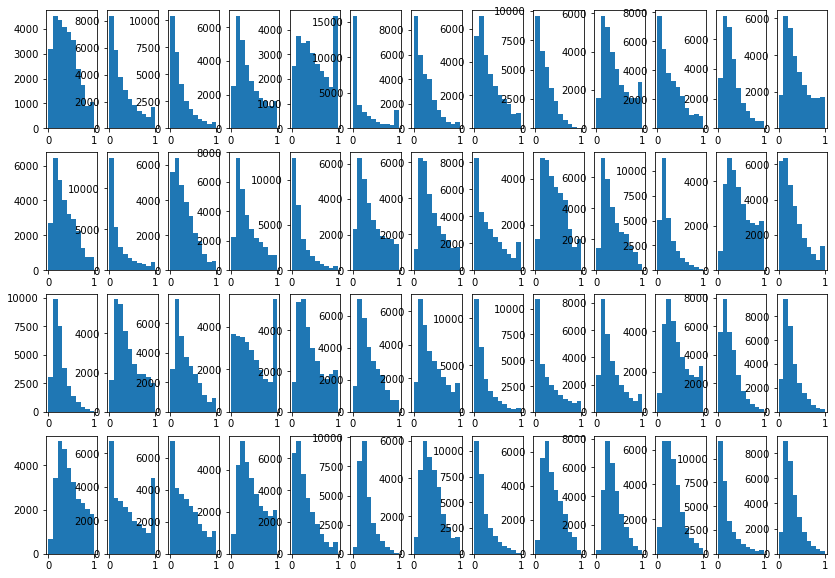

In [58]:
plot_all_marker_distributions(norm_data, 4, 13)

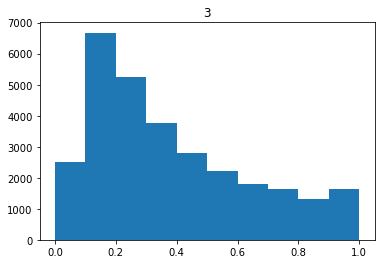

In [59]:
plot_marker_distribution(norm_data, 3)

In [60]:
batch_size = 400
train_loader = torch.utils.data.DataLoader(train_data, batch_size = batch_size, shuffle = True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size = batch_size, shuffle = False)

In [61]:
def train(svi, train_loader, use_cuda=False):
    # initialize loss accumulator
    epoch_loss = 0.
    # do a training epoch over each mini-batch x returned
    # by the data loader
    for x, in train_loader:
        # if on GPU put mini-batch into CUDA memory
        if use_cuda:
            x = x.cuda()
        # do ELBO gradient and accumulate loss
        epoch_loss += svi.step(x)

    # return epoch loss
    normalizer_train = len(train_loader.dataset)
    total_epoch_loss_train = epoch_loss / normalizer_train
    return total_epoch_loss_train

def evaluate(svi, test_loader, use_cuda=False):
    # initialize loss accumulator
    test_loss = 0.
    # compute the loss over the entire test set
    for x, in test_loader:
        # if on GPU put mini-batch into CUDA memory
        if use_cuda:
            x = x.cuda()
        # compute ELBO estimate and accumulate loss
        test_loss += svi.evaluate_loss(x)
    normalizer_test = len(test_loader.dataset)
    total_epoch_loss_test = test_loss / normalizer_test
    return total_epoch_loss_test

In [62]:
NUM_EPOCHS = 50
USE_CUDA = False
TEST_FREQUENCY = 5

train_elbo = []
test_elbo = []

# training loop
for epoch in range(NUM_EPOCHS):
    total_epoch_loss_train = train(svi, train_data, use_cuda=USE_CUDA)
    train_elbo.append(-total_epoch_loss_train)
    print("[epoch %03d]  average training loss: %.4f" % (epoch, total_epoch_loss_train))

    if epoch % TEST_FREQUENCY == 0:
        # report test diagnostics
        total_epoch_loss_test = evaluate(svi, test_data, use_cuda=USE_CUDA)
        test_elbo.append(-total_epoch_loss_test)
        print("[epoch %03d] average test loss: %.4f" % (epoch, total_epoch_loss_test))

[epoch 000]  average training loss: 1434.3398
[epoch 000] average test loss: 130.5694
[epoch 001]  average training loss: 1424.6402
[epoch 002]  average training loss: 1423.2823
[epoch 003]  average training loss: 1422.7581
[epoch 004]  average training loss: 1422.4485
[epoch 005]  average training loss: 1422.2308
[epoch 005] average test loss: 130.3614
[epoch 006]  average training loss: 1422.1027
[epoch 007]  average training loss: 1422.0118
[epoch 008]  average training loss: 1421.9729
[epoch 009]  average training loss: 1421.9068
[epoch 010]  average training loss: 1421.9221
[epoch 010] average test loss: 130.3002
[epoch 011]  average training loss: 1421.8946
[epoch 012]  average training loss: 1421.8514
[epoch 013]  average training loss: 1421.8089
[epoch 014]  average training loss: 1421.7782
[epoch 015]  average training loss: 1421.7907
[epoch 015] average test loss: 130.2813
[epoch 016]  average training loss: 1421.7678
[epoch 017]  average training loss: 1421.7195
[epoch 018] 

In [ ]:
for x, in train_data: print(x)

In [ ]:
%%bash 
conda install matplotlib -y

In [13]:
import matplotlib.pyplot as plt

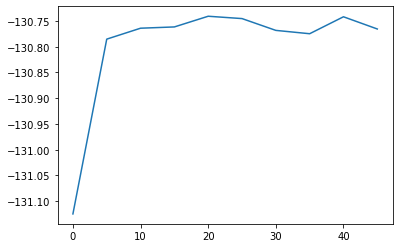

In [14]:
plt.plot([i for i in range(0, len(train_elbo),5)], test_elbo )

# New heading